# Beyond the port

Most of Spynach is a port, checked stage by stage against Spinach. This guide
collects the add-ons originating here: features with no Spinach counterpart,
and modules that live beside the port. Each entry has a
short example and points to the guide that covers it in depth. The companion
notebook is [`notebooks/beyond-the-port.ipynb`](beyond-the-port.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/beyond-the-port.ipynb)).

*Generated from [`docs/beyond-the-port.md`](../beyond-the-port.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Coherence transfer pathway selection: `ctps`](#Coherence-transfer-pathway-selection:-ctps)
2. [Non-ideal pulses and cogwheel cycle search](#Non-ideal-pulses-and-cogwheel-cycle-search)
3. [Interactive figures and static copies](#Interactive-figures-and-static-copies)
4. [Checking results: `compare`, the parity page, timed reports](#Checking-results:-compare,-the-parity-page,-timed-reports)
5. [Executable documentation, Colab, contributed notebooks](#Executable-documentation,-Colab,-contributed-notebooks)

## Coherence transfer pathway selection: `ctps`

Spinach simulates the spin dynamics of a sequence; it does not enumerate the
coherence transfer pathways a phase cycle or gradient scheme lets through.
`ctps`, a separate module in this repository (`import ctps`, no dependency on
`spynach`), ports the CCCP.m and CCCP++ programs (Jerschow & Müller, *J. Magn.
Reson.* 134, 17 (1998); Jerschow & Kumar, *J. Magn. Reson.* 160, 59 (2003)):
every pathway the allowed orders permit, weighted by the phase cycle, the
gradients, diffusion and the pulses, ranked, and drawn. A spin echo whose
180° pulse is 0.2 rad short, with a two-step cycle on that pulse and a crusher
pair around it: the cycle alone would let the non-inverted pathway through,
the crushers dephase it, and the pulse error sets how much of it exists:

In [1]:
import numpy as np

from ctps import AllowedOrders, Nucleus, Period, PhaseCycle, Pulse, Sequence, simulate

ms = 1e-3
echo = Sequence(
    nuclei=(Nucleus("1H"),),
    pulses=(Pulse("1H", label="90"), Pulse("1H", "imperfect_180", beta=0.2, label="180")),
    periods=(Period(), Period.with_gradient(5 * ms, "z", 0.1, 1 * ms), Period.with_gradient(5 * ms, "z", 0.1, 1 * ms)),
    allowed={"1H": AllowedOrders.standard(1, 3)},
    diffusion=2e-9,
)
cycle = PhaseCycle.explicit(phases=[[0], [0, 2]], receiver=[0, 0], base=4)
result = simulate(echo, cycle, wanted=[(0, 1, -1)], cutoff=0)
for row in result.table():
    print(row["pathway"], f"pc {row['pc']:.2f}  grad {row['grad']:.4f}  diff {row['diff']:.3f}  pulse {row['pulse']:.3f}  total {row['total']:.2e}")

[0, 1, -1] pc 1.00  grad 1.0000  diff 0.993  pulse 1.000  total 9.93e-01
[0, -1, -1] pc 1.00  grad 0.0037  diff 0.965  pulse 0.010  total 3.61e-05


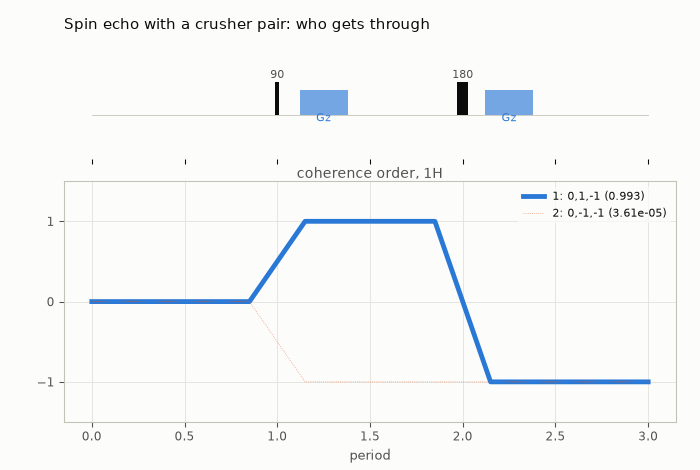

In [2]:
from ctps.plot import plot_pathways

plot_pathways(result, top=5, title="Spin echo with a crusher pair: who gets through")

The explorer draws the sequence above the coherence orders, scales every
pathway's line width by its weight, and steps through the pathways with a
slider, listing the phase-cycle, gradient, diffusion and pulse factors of each.
[Coherence transfer pathways](ctps.ipynb) is the full guide; `src/ctps/README.md`
says how to remove the module without touching Spynach.

## Non-ideal pulses and cogwheel cycle search

Two parts of `ctps` are new even relative to the programs it ports. Each pulse
can be declared a perfect 180°, an imperfect 180° (deviation `beta`, axis tilt
`epsilon`) or a small-flip-angle pulse, and the leakage of every coherence
transfer follows Jerschow, *J. Chem. Phys.* 113, 979 (2000), whose formulas and
tables were recomputed before use. And `find_cycle` searches cogwheel phase
cycles by exact integer arithmetic, testing all winding numbers at once as one
integer matrix product, with the symmetry reductions of the literature, while
`coverage` finds the best cycle for a fixed number of steps and
`crusher_scheme` optimises gradient areas with the DOTCOPS objective:

In [3]:
from ctps import coverage, find_cycle, hcl_cycle

mqmas = Sequence.simple(n_pulses=3, p_max=3)
print("Hughes-Carravetta-Levitt construction:", hcl_cycle([3, 1], [3, 3]).cog_string())
print("smallest cycle found:", find_cycle(mqmas, [(0, 3, 1, -1)]).best.cog_string())
print("best 8-step cycle for sLASER:", coverage(Sequence.simple(5, 1), [(0, -1, 1, -1, 1, -1)], 8).best.cog_string())

Hughes-Carravetta-Levitt construction: COG23(0,3,4;14)
smallest cycle found: COG23(0,1,9;20)
best 8-step cycle for sLASER: COG8(0,1,0,1,0;4)


## Interactive figures and static copies

Spinach draws into MATLAB figures. Spynach's `plot_1d` and `plot_2d` follow
Spinach's parameters but return interactive Plotly figures; `plot_fid`,
`plot_time_series` and `plot_trajan` have no Spinach counterpart, and
`figure_png` turns any of them into a PNG (through Kaleido when it can run,
otherwise a Matplotlib redraw) for GitHub, reports and papers. The notebooks in
this repository are saved with both the interactive figure and its PNG copy,
which is what GitHub's viewer shows.

In [4]:
import spynach

spin_system = spynach.create(
    {"isotopes": ["1H", "1H"], "magnet": 14.1}, {"zeeman": {"scalar": [1.0, 1.1]}, "coupling": {"scalar": [[0, 12.0], [0, 0]]}}
)
spin_system = spynach.basis(spin_system, {"formalism": "zeeman-hilb", "approximation": "none"})
parameters = {"spins": ["1H"], "offset": 630, "sweep": 200, "npoints": 512,
              "rho0": spynach.state(spin_system, "L+", "1H"), "coil": spynach.state(spin_system, "L+", "1H")}
fid = spynach.apodisation(spynach.liquid(spin_system, spynach.acquire, parameters, "nmr"), [("exp", 6)])

46 KB of PNG


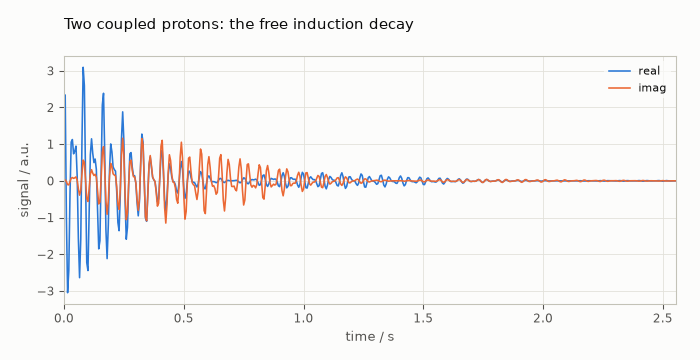

In [5]:
from spynach.plotting import figure_png, plot_fid

fig = plot_fid(fid, parameters, title="Two coupled protons: the free induction decay")
print(f"{len(figure_png(fig, scale=1)) / 1024:.0f} KB of PNG")
fig

## Checking results: `compare`, the parity page, timed reports

Spinach has no reference implementation to compare against; Spynach has
Spinach. `spynach.oracle.compare` is the normwise comparison behind the parity
suite and works on any pair of arrays, so a Spinach `.mat` result can be checked
against a Spynach run (see [Checking your own workflow against Spinach](coming-from-spinach.ipynb#Checking-your-own-workflow-against-Spinach)).
[Parity with Spinach](../parity.md), regenerated from the test suite, lists every
fixture case, tolerance and measured difference, and
[`comparison/README.md`](../../comparison/README.md) is the protocol for timed and
profiled Spinach-vs-Spynach runs with an HTML report.

In [6]:
from spynach.oracle import compare

reference = fid * (1 + 1e-11)  # stands in for the same FID computed by Spinach
print(compare(fid, reference, rtol=1e-9, atol=0, name="fid"))

PASS fid (512,): rel_err=1.000e-11 max_abs_err=3.146e-11 ref_norm=1.318e+01 (rtol=1e-09, atol=0)


## Executable documentation, Colab, contributed notebooks

Every guide in `docs/` is Markdown whose Python blocks run in the test suite,
with a notebook generated from it and saved with outputs
(`docs/build_notebooks.py`). `docs/colab/quick-start.ipynb` installs Spynach
in Google Colab and runs the quick-start example in the browser. `user_py/`
holds contributed notebooks, such as the triple-quantum build-up of a 23Na
spin under quadrupolar relaxation, beside the contributed Spinach scripts in
`user_ml/` and their translations in `examples/user_ml/`.